---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

In [240]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---

## Group 19

- Raysha Erviandika Putra 13524050
- Mahmudia Kimdaro Amin 13524083
- Billie Bhaskara Wibawa 13524024
- Anindya Naufal Pinasthika 13524013
- Muhammad Fatih Irkham Mauludi 13524004

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Notebook ini berisi pengerjaan terkait tugas besar IF3170 Intelegensi Artifisial, yang dilakukan terkait algoritma-algoritma supervised learning.

## Overview

Pada tugas ini akan dilakukan perancangan dan implementasi beberapa varian algoritma supervised learning, dimana akan dilakukan eksperimen, dan analisis hasilnya juga.

## Aim

Tugas Besar II pada kuliah IF3170 Intelegensi Buatan bertujuan agar peserta kuliah mendapatkan wawasan tentang bagaimana cara mengimplementasikan dan mengevaluasi algoritma-algoritma supervised learning untuk menyelesaikan permasalahan berupa studi kasus yang relevan terhadap industri.

## Metric

Pemahaman terhadap algorithma supervised learning serta kemampuan menggunakannya untuk melakukan klasifikasi dataset.

## Dataset

Dataset berisi rekaman booking dari sebuah properti akomodasi tertentu. Informasi yang disediakan oleh dataset diantaranya yaitu daftar tamu, deskripsi penggunaan properti, deskripsi penginapan, saluran booking, harga booking, dan lain-lain. Target klasifikasi  utama yang ada pada dataset yaitu apakah tamu akan melakukan pembatalan booking atau tidak.

## Approach

Klasifikasi target kelas pada dataset akan dilakukan membuat model supervised learning menggunakan lima algoritma, yaitu Decision Tree Learning, K-Nearest-Neighbor, Support Vector Machine, Logistic Regression, dan Naive-Bayes. Model untuk klasifikasi akan dibuat dari algoritma yang diimplementasi dari scratch, tetapi akan tetapi dibandingkan dengan algoritma milik scikit-learn. Tentu diawal akan dilakukan tahapan-tahapan Exploratory Data Analysis terlebih dahulu.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [241]:
# %pip install -q numpy pandas matplotlib seaborn

## Import Libraries

Import library custom yang akan digunakan pada keseluruhan notebok.

In [242]:
import os
import random

from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA


from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

Import custom library yang berisi algoritma supervised learning, hasil implementasi from scratch

In [243]:
from kagglemethis.DTL import DTL
from kagglemethis.LogisticRegression import LogisticRegression as LR
from kagglemethis.NaiveBayes import NaiveBayes
from kagglemethis.KNN import KNN
from kagglemethis.SVM import SVC as CustomSVC, plot_decision_boundary

## Settings

Buat settings terkait parameter-parameter dan path yang digunakan.

In [244]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

Tambahkan seeding sehingga hasil akhir dapat direproduksi dengan baik dan deterministik. Tanpa seed maka hasil dapat berubah-rubah dan sulit dikontrol.

In [245]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Load dataset kompetisi, perhatikan bahwa kolom `id` dianggap sebagai teks walaupun beberapa nilai terlihat seperti numerik.

In [246]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding dilakukan pertama dengan melihat berbagai atribut dan karakteristik dataset sehingga pemrosesan lanjutan dan pembuatan model dapat dilakukan dengan baik.

## Describe Data

Deskripsi ukuran, tipe data, dan karakteristik tiap kolom atribut.

In [247]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)


Training shape: (27373, 19)
Testing shape: (6844, 18)


In [248]:
print("============= Overview data training ===========")
display(train_df.head())

print("=========== Overview karakteristik data training ===========")
train_df.info()

print("=========== Overview statistik data training ===========")
display(train_df.describe(include="all").T)

print("=========== Overview kelas target ===========")
display(
    train_df["is_canceled"]
    .value_counts()
    .rename_axis("is_canceled")
    .reset_index(name="count")
)

============= Overview data training ===========


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


=========== Overview karakteristik data training ===========
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returnin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27373,27373,57152f82,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_adults,26564.0,NaN,NaN,NaN,1.845242,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,NaN,NaN,NaN,0.117388,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,NaN,NaN,NaN,0.814854,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,NaN,NaN,NaN,2.206517,1.421603,0.0,1.0,2.0,3.0,17.0
meal_package,25613,4,Breakfast,19654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
needs_parking,26291.0,NaN,NaN,NaN,0.0302,0.171142,0.0,0.0,0.0,0.0,1.0
room_category,26371,7,Type B,20447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_before_arrival,26250.0,NaN,NaN,NaN,85.379429,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,NaN,NaN,NaN,2023.820115,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


=========== Overview kelas target ===========


,is_canceled,count
0,0,18404
1,1,8969


## Explore Data

This part covers distributions and relationships between attributes.


=========== Visualisasi distribusi kelas target ===========


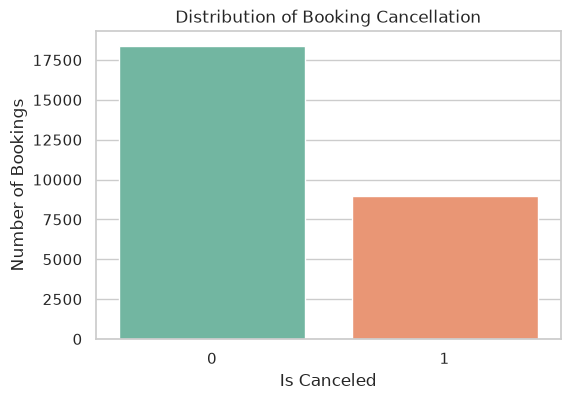


=========== Persentase kelas target ===========
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64

=========== Visualisasi atribut numerik ===========


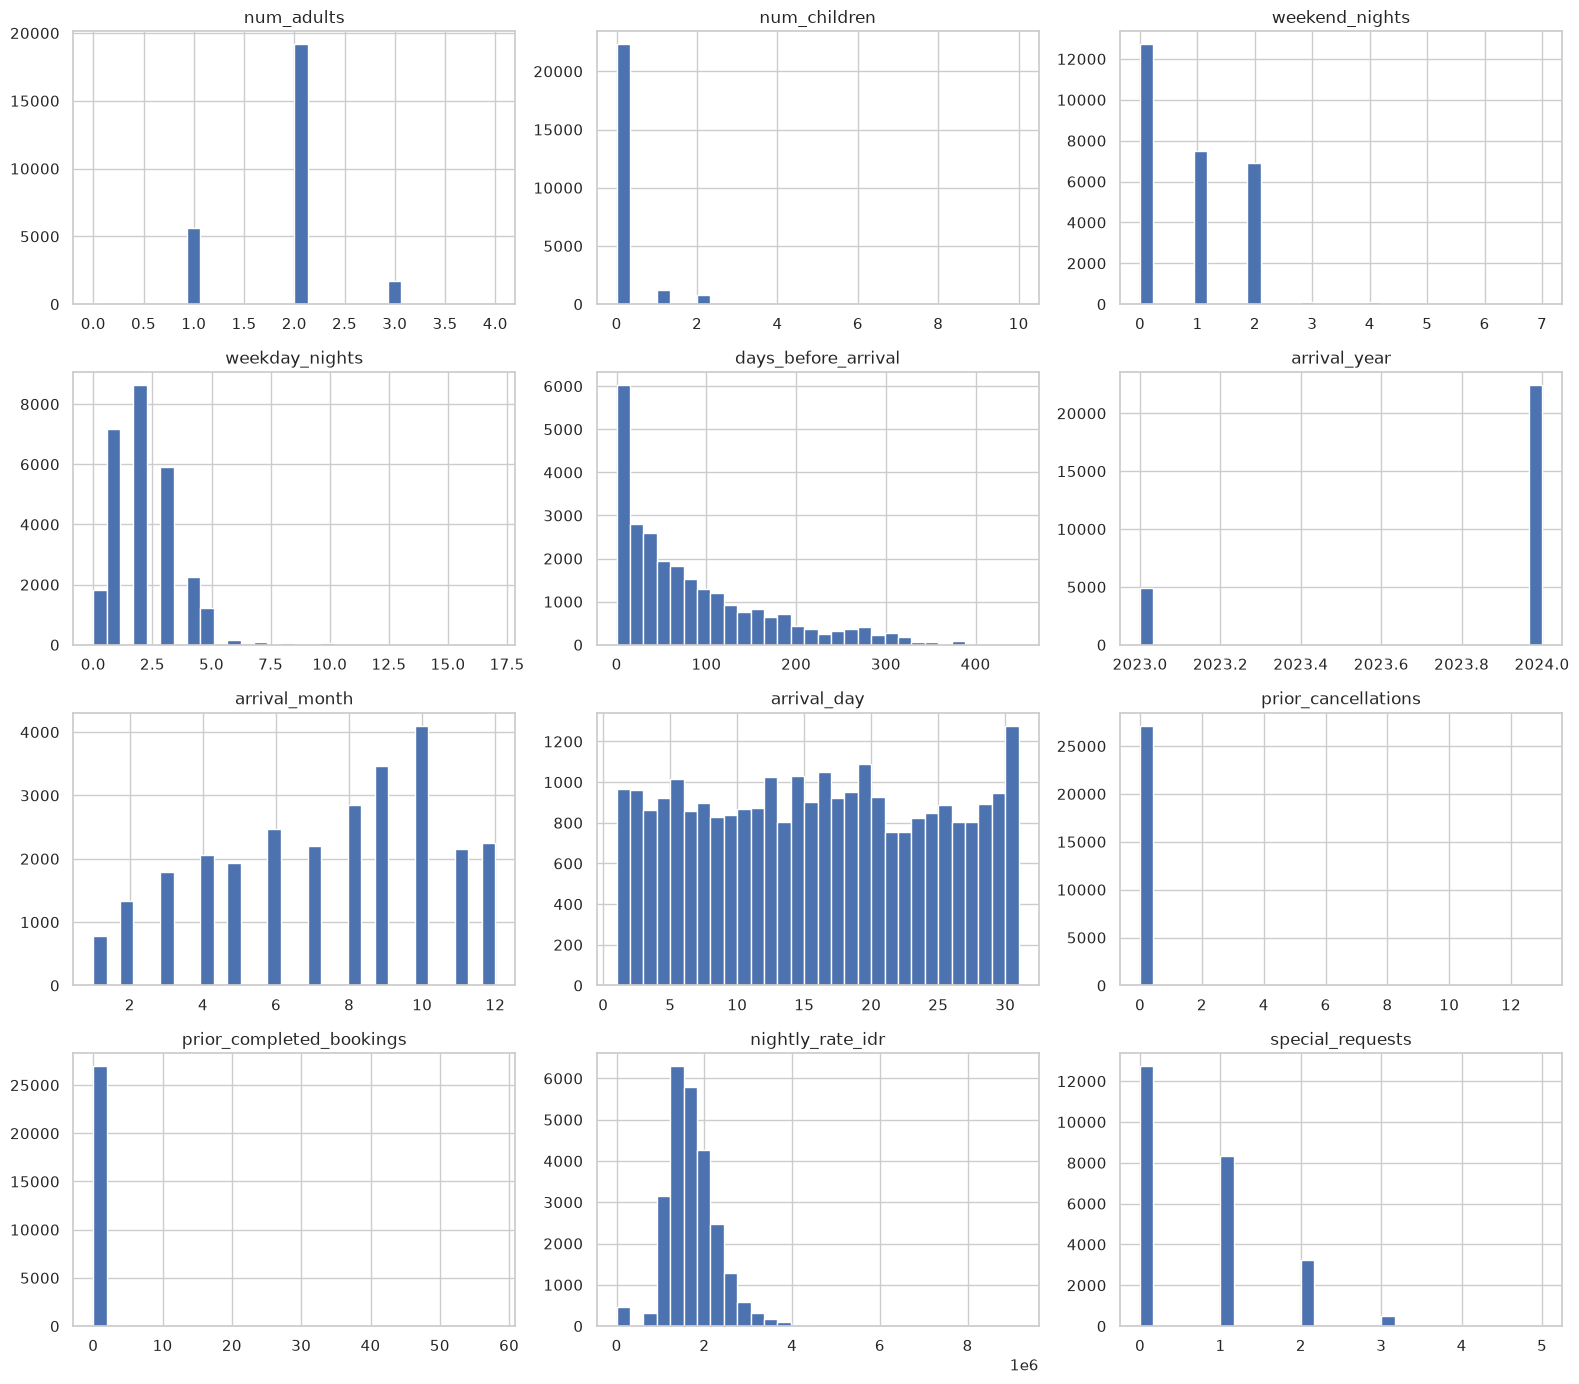

In [249]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="is_canceled",
    hue="is_canceled",
    palette="Set2",
    legend=False,
    ax=ax
)

ax.set_title("Distribution of Booking Cancellation")
ax.set_xlabel("Is Canceled")
ax.set_ylabel("Number of Bookings")

print("\n=========== Visualisasi distribusi kelas target ===========")
plt.show()


print("\n=========== Persentase kelas target ===========")
print(
    train_df["is_canceled"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

numeric_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

print("\n=========== Visualisasi atribut numerik ===========")
train_df[numeric_cols].hist(
    bins=30,
    figsize=(16, 14),
    layout=(4, 3)
)
plt.tight_layout()
plt.show()

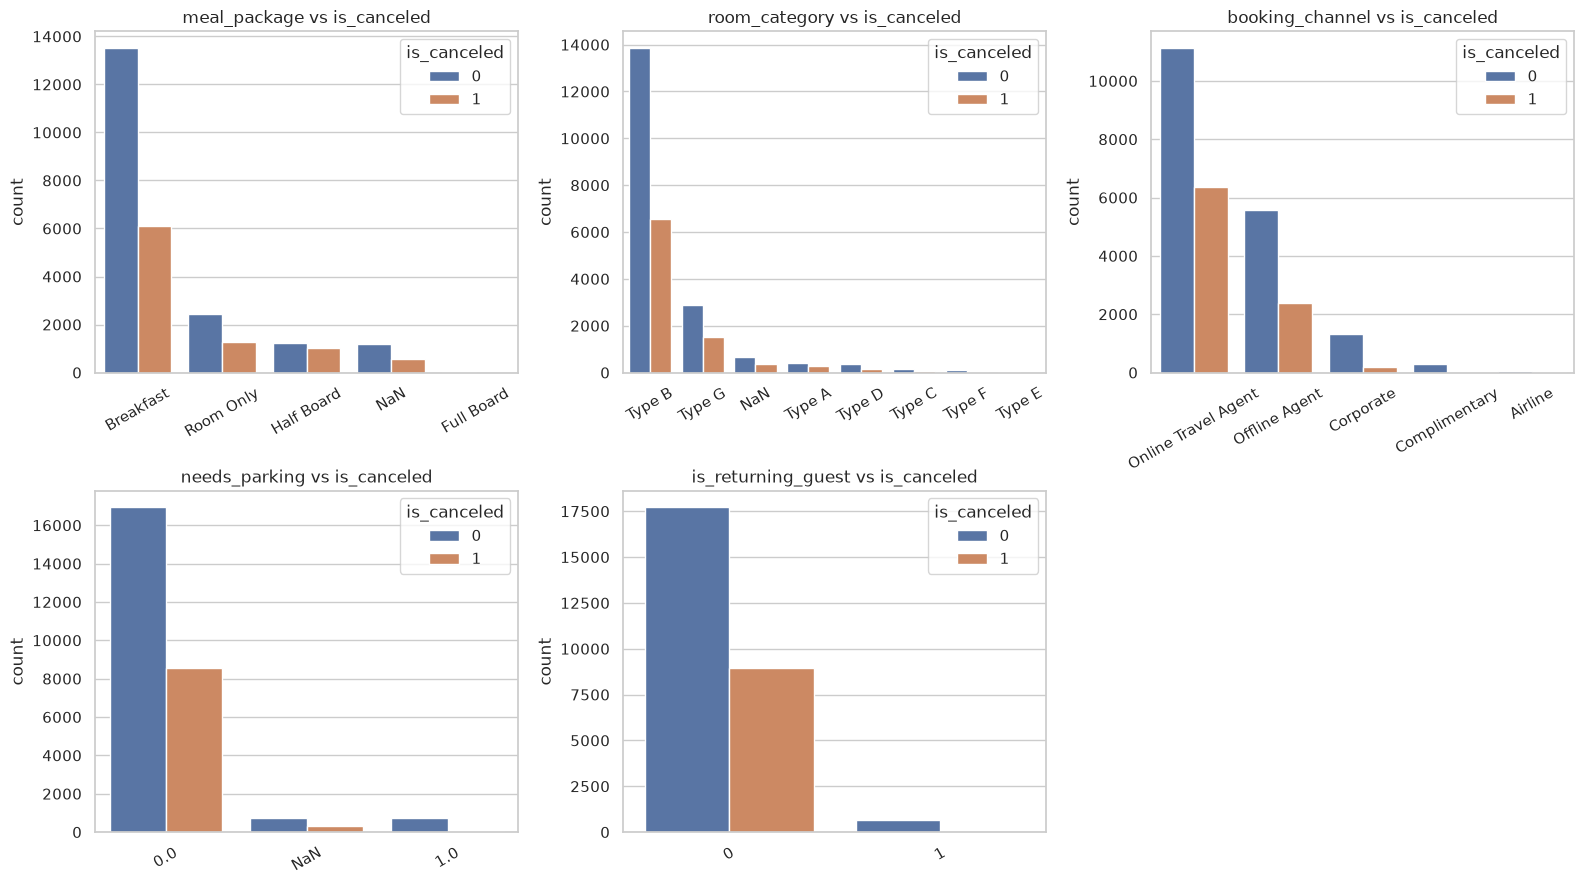

In [250]:
cat_cols = [
    "meal_package",
    "room_category",
    "booking_channel",
    "needs_parking",
    "is_returning_guest",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    plot_series = train_df[col].astype(str).fillna("NaN").astype(str)

    sns.countplot(
        x=plot_series,
        hue=train_df["is_canceled"],
        order=plot_series.value_counts().index,
        ax=axes[i],
    )
    axes[i].set_title(f"{col} vs is_canceled")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


=========== Visualisasi persentase melakukan cancel berdasarkan atribut kategorikal lainnya ===========


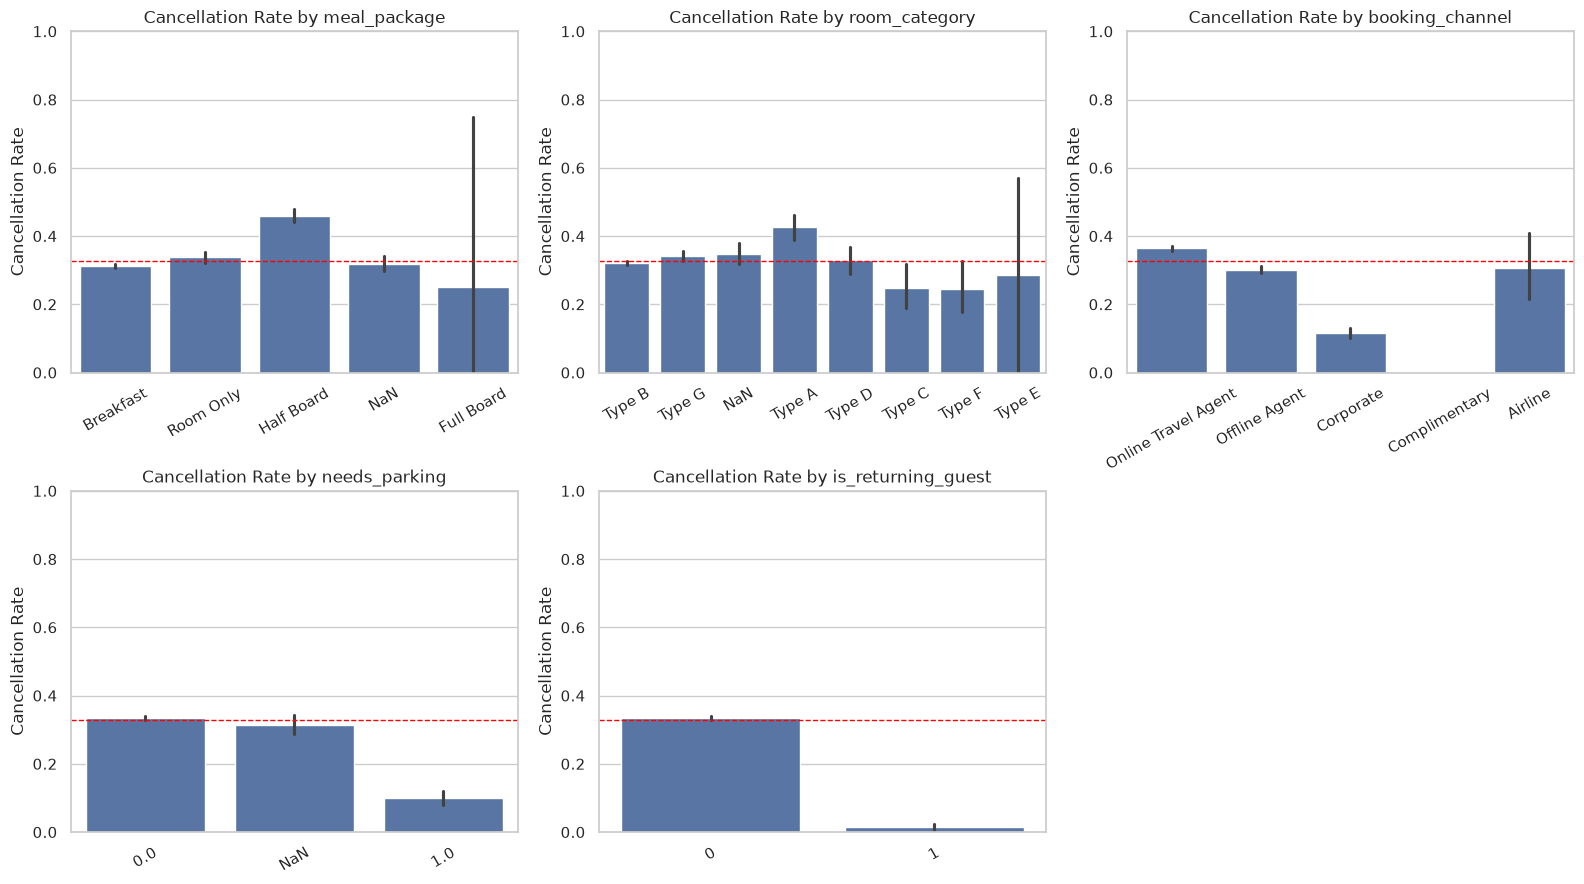

In [251]:
print("\n=========== Visualisasi persentase melakukan cancel berdasarkan atribut kategorikal lainnya ===========")

cat_cols = [
    "meal_package",
    "room_category",
    "booking_channel",
    "needs_parking",
    "is_returning_guest",
]

baseline_rate = train_df["is_canceled"].mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    plot_series = train_df[col].astype(str).fillna("NaN").astype(str)
    order = plot_series.value_counts().index

    sns.barplot(
        x=plot_series,
        y=train_df["is_canceled"],
        order=order,
        ax=axes[i],
    )
    axes[i].axhline(baseline_rate, color="red", linestyle="--", linewidth=1, label="Overall Avg")
    axes[i].set_title(f"Cancellation Rate by {col}")
    axes[i].set_ylabel("Cancellation Rate")
    axes[i].set_xlabel("")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


=========== Distribusi outlier berdasarkan kelas target ===========


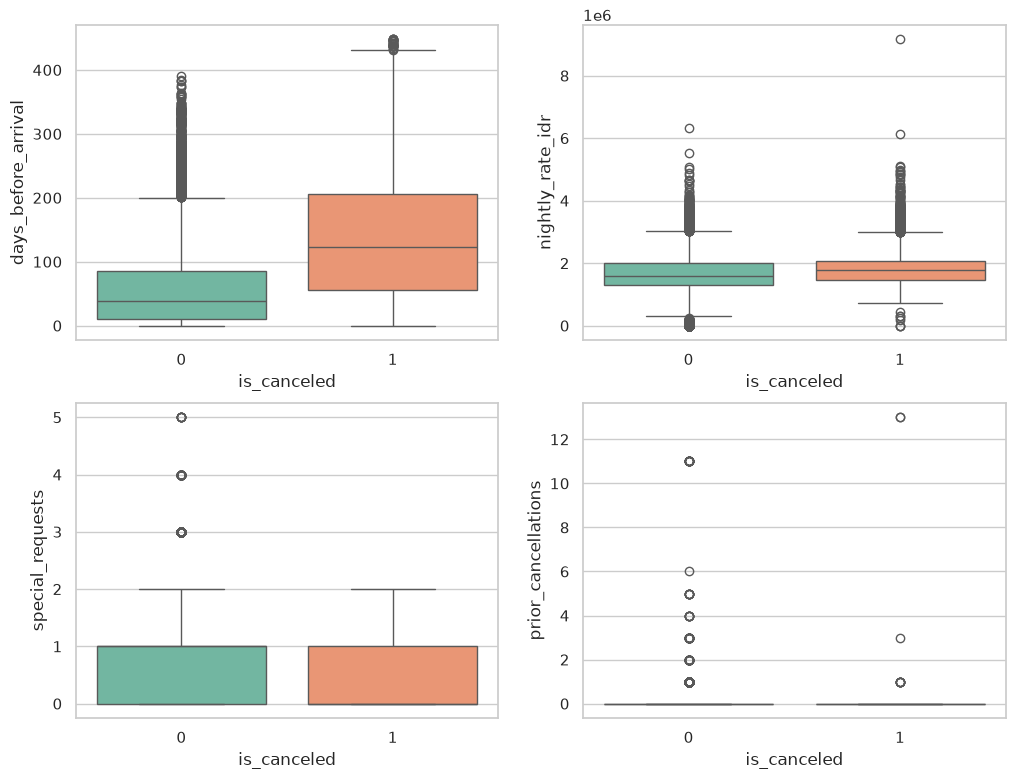

In [252]:
selected_cols = [
    "days_before_arrival",
    "nightly_rate_idr",
    "special_requests",
    "prior_cancellations"
]

print("\n=========== Distribusi outlier berdasarkan kelas target ===========")
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, selected_cols):
    sns.boxplot(
        data=train_df,
        x="is_canceled",
        y=col,
        hue="is_canceled",
        palette="Set2",
        legend=False,
        showfliers=True,
        ax=ax
    )

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [253]:
missing = pd.DataFrame({
    "count": train_df.isna().sum(),
    "percentage": train_df.isna().mean() * 100
}).sort_values("count", ascending=False)

print("\n=========== Statistik missing value per-atribut ===========")
display(missing)

print("\n=========== Statistik row duplicate ===========")
print("Duplicate IDs:", train_df["id"].duplicated().sum())
print("Duplicate rows:", train_df.duplicated().sum())

feature_cols = train_df.columns.drop("id")
print("Duplicates excluding ID:", train_df.duplicated(subset=feature_cols).sum())

binary_cols = [
    "needs_parking",
    "is_returning_guest",
    "is_canceled"
]

for col in binary_cols:
    print(f"\n=========== Statistik atribut biner '{col}' ===========")
    print(train_df[col].value_counts(dropna=False))

nonnegative_cols = [
    "num_adults", "num_children",
    "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr",
    "special_requests"
]

print("\n=========== Statistik nilai invalid untuk atribut non-negatif ===========")
display((train_df[nonnegative_cols] < 0).sum())

arrival_dates = pd.to_datetime(
    dict(
        year=train_df["arrival_year"],
        month=train_df["arrival_month"],
        day=train_df["arrival_day"]
    ),
    errors="coerce"
)

print(f"Invalid arrival dates: {arrival_dates.isna().sum()} ({arrival_dates.isna().mean() * 100:.2f}%)")

no_guests = (train_df["num_adults"].fillna(0) == 0) & (train_df["num_children"].fillna(0) == 0)
no_nights = (train_df["weekend_nights"] + train_df["weekday_nights"]) == 0
print(f"Invalid row based on total guests: {no_guests.sum()} ({no_guests.mean() * 100:.2f}%)")
print(f"Invalid row based on total nights: {no_nights.sum()} ({no_nights.mean() * 100:.2f}%)")



=========== Statistik missing value per-atribut ===========


,count,percentage
num_children,3035,11.087568
special_requests,2500,9.133087
nightly_rate_idr,2038,7.445293
meal_package,1760,6.429693
days_before_arrival,1123,4.102583
needs_parking,1082,3.952800
room_category,1002,3.660541
num_adults,809,2.955467
id,0,0.000000
weekend_nights,0,0.000000



=========== Statistik row duplicate ===========
Duplicate IDs: 0
Duplicate rows: 0
Duplicates excluding ID: 64

=========== Statistik atribut biner 'needs_parking' ===========
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64

=========== Statistik atribut biner 'is_returning_guest' ===========
is_returning_guest
0    26684
1      689
Name: count, dtype: int64

=========== Statistik atribut biner 'is_canceled' ===========
is_canceled
0    18404
1     8969
Name: count, dtype: int64

=========== Statistik nilai invalid untuk atribut non-negatif ===========


num_adults                  0
num_children                0
weekend_nights              0
weekday_nights              0
days_before_arrival         0
prior_cancellations         0
prior_completed_bookings    0
nightly_rate_idr            0
special_requests            0
dtype: int64

Invalid arrival dates: 0 (0.00%)
Invalid row based on total guests: 748 (2.73%)
Invalid row based on total nights: 64 (0.23%)


In [254]:
print("\n=========== Persentase missing value fitur numerik berdasarkan kelas target ===========")

missing_cols = train_df.columns[
    train_df.isna().any()
].drop("is_canceled", errors="ignore")

results = []

for col in missing_cols:
    temp = train_df.assign(
        is_missing=train_df[col].isna()
    )

    rates = temp.groupby("is_missing")["is_canceled"].mean()

    results.append({
        "feature": col,
        "missing_rate": temp["is_missing"].mean(),
        "cancel_rate_missing": rates.get(True, float("nan")),
        "cancel_rate_present": rates.get(False, float("nan"))
    })

display(pd.DataFrame(results))


=========== Persentase missing value fitur numerik berdasarkan kelas target ===========


,feature,missing_rate,cancel_rate_missing,cancel_rate_present
0,num_adults,0.029555,0.334981,0.327436
1,num_children,0.110876,0.328171,0.327595
2,meal_package,0.064297,0.319318,0.328232
3,needs_parking,0.039528,0.312384,0.328287
4,room_category,0.036605,0.348303,0.326874
5,days_before_arrival,0.041026,0.311665,0.328343
6,nightly_rate_idr,0.074453,0.313052,0.328834
7,special_requests,0.091331,0.408400,0.319543


In [255]:
cols = [
    "special_requests",
    "prior_cancellations",
    "prior_completed_bookings",
    "is_returning_guest",
    "needs_parking"
]

for col in cols:
    print(f"\n=========== Persentase cancel berdasarkan nilai atribut '{col}' ===========")
    
    summary = (
        train_df.groupby(col, dropna=False)["is_canceled"]
        .agg(
            total="count",
            cancellation_rate="mean"
        )
    )

    display(summary)


=========== Persentase cancel berdasarkan nilai atribut 'special_requests' ===========


,total,cancellation_rate
special_requests,,
0.0,12730,0.432050
1.0,8334,0.238061
2.0,3246,0.142945
3.0,496,0.000000
4.0,60,0.000000
5.0,7,0.000000
NaN,2500,0.408400



=========== Persentase cancel berdasarkan nilai atribut 'prior_cancellations' ===========


,total,cancellation_rate
prior_cancellations,,
0,27132,0.330201
1,143,0.048951
2,33,0.000000
3,30,0.033333
4,6,0.000000
5,7,0.000000
6,1,0.000000
11,19,0.000000
13,2,1.000000



=========== Persentase cancel berdasarkan nilai atribut 'prior_completed_bookings' ===========


,total,cancellation_rate
prior_completed_bookings,,
0,26773,0.334852
1,181,0.011050
2,90,0.000000
3,51,0.000000
4,37,0.027027
5,44,0.000000
6,28,0.000000
7,17,0.000000
8,19,0.000000



=========== Persentase cancel berdasarkan nilai atribut 'is_returning_guest' ===========


,total,cancellation_rate
is_returning_guest,,
0,26684,0.335744
1,689,0.014514



=========== Persentase cancel berdasarkan nilai atribut 'needs_parking' ===========


,total,cancellation_rate
needs_parking,,
0.0,25497,0.335373
1.0,794,0.100756
NaN,1082,0.312384



=========== Statistik cancel berdasarkan durasi hari sebelum datang ===========


,total,cancellation_rate
days_before_arrival,,
0-7 days,4116,0.096453
8-30 days,4868,0.183443
31-60 days,4501,0.230171
61-90 days,3346,0.282726
91-180 days,5573,0.451283
>180 days,3846,0.736349


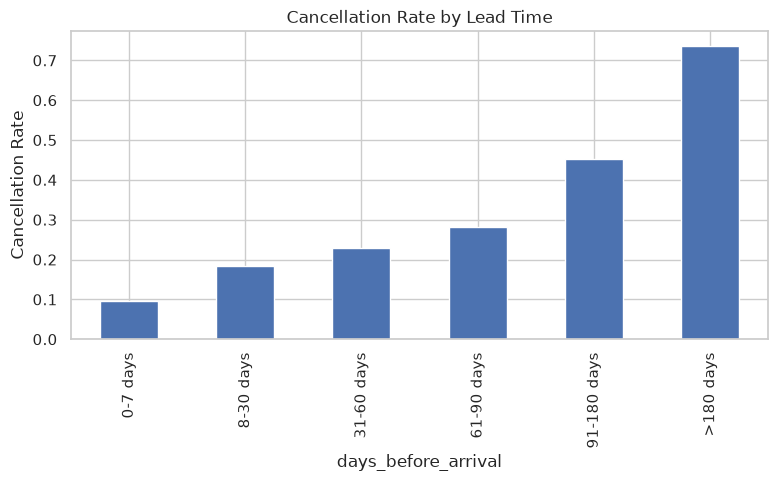

In [256]:
bins = [-1, 7, 30, 60, 90, 180, float("inf")]
labels = [
    "0-7 days",
    "8-30 days",
    "31-60 days",
    "61-90 days",
    "91-180 days",
    ">180 days"
]

lead_time_group = pd.cut(
    train_df["days_before_arrival"],
    bins=bins,
    labels=labels
)

summary = (
    train_df.groupby(
        lead_time_group,
        observed=True
    )["is_canceled"]
    .agg(
        total="count",
        cancellation_rate="mean"
    )
)

print("\n=========== Statistik cancel berdasarkan durasi hari sebelum datang ===========")
display(summary)

summary["cancellation_rate"].plot(
    kind="bar",
    figsize=(9, 4),
    title="Cancellation Rate by Lead Time"
)

plt.ylabel("Cancellation Rate")
plt.show()

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [257]:
TARGET = "is_canceled"
ID_COL = "id"

X = train_df.drop(columns=[TARGET, ID_COL])
y = train_df[TARGET].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=CFG.SEED,
    stratify=y
)

X_test = test_df.drop(columns=[ID_COL]).copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (21898, 17)
Validation: (5475, 17)
Testing: (6844, 17)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [258]:
FEATURE_COLS = X_train.columns.tolist()

NUMERIC_COLS = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

CATEGORICAL_COLS = [
    "meal_package",
    "room_category",
    "booking_channel"
]

BINARY_COLS = [
    "needs_parking",
    "is_returning_guest"
]

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [259]:
X_train = X_train.copy()
X_val = X_val.copy()
X_test = test_df.drop(columns=["id"]).copy()

def clean_missing_values(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    adults_median = X_train["num_adults"].median()
    childs_median = X_train["num_children"].median()
    days_median = X_train["days_before_arrival"].median()
    room_rate_medians = X_train.groupby("room_category")["nightly_rate_idr"].median().to_dict()
    global_rate_median = X_train["nightly_rate_idr"].median()

    for df in [X_train] + X_tests:
        # Save into a new feature for these missing attribute
        df["special_requests_is_missing"] = df["special_requests"].isna().astype(int)
        df["nightly_rate_is_missing"] = df["nightly_rate_idr"].isna().astype(int)

        # Fill missing binary features with 0
        df["special_requests"] = df["special_requests"].fillna(0)
        df["needs_parking"] = df["needs_parking"].fillna(0)

        # Fill categorical nulls with "Unknown" 
        df["meal_package"] = df["meal_package"].astype("object").fillna("Unknown")
        df["room_category"] = df["room_category"].astype("object").fillna("Unknown")

        # Fill numeric features using X_train medians 
        df["num_adults"] = df["num_adults"].fillna(adults_median)
        df["num_children"] = df["num_children"].fillna(childs_median)
        df["days_before_arrival"] = df["days_before_arrival"].fillna(days_median)

        # Fill price rate using X_train median grouped based on by room_category for rate
        mapped_medians = df["room_category"].map(room_rate_medians).fillna(global_rate_median)
        df["nightly_rate_idr"] = df["nightly_rate_idr"].fillna(mapped_medians)
    
    return X_train, X_tests

X_train, (X_val, X_test) = clean_missing_values(X_train, [X_val, X_test])

# Verification
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert df.isna().sum().sum() == 0, f"Missing values imputation failed for {name}!"

BINARY_COLS += ["special_requests_is_missing", "nightly_rate_is_missing"]
FEATURE_COLS += ["special_requests_is_missing", "nightly_rate_is_missing"]

print("Handled missing values")

Handled missing values


### Duplicates

This part covers repeated records.

In [260]:
# Since ID is dropped so we can just drop based on exact row duplicates on X_train

def clean_duplicates(X_train, y_train):
    X_train = X_train.drop_duplicates(keep="first").copy()
    y_train = y_train.loc[X_train.index].copy()
    return X_train, y_train

X_train, y_train = clean_duplicates(X_train, y_train)
assert X_train.duplicated().sum() == 0, "Duplicates still exist"
assert len(X_train) == len(y_train), "Duplicate handling failed causing mismatch"

print("Handled duplicates")

Handled duplicates


### Outliers

This part covers values far from the rest of the data.

In [261]:
outlier_summary = X_train[NUMERIC_COLS].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

print("============== Outlier summary (before) ==============")
display(
    outlier_summary[
        ["min", "1%", "25%", "50%", "75%", "99%", "max"]
    ]
)

# Only nightly_rate_idr that has significant outlier, other attributes that has outlier correlate with the cancellation rate so better not clip it
def clean_outliers(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    rate_upper_cap = X_train["nightly_rate_idr"].quantile(0.999)
    for df in [X_train] + X_tests:
        df["nightly_rate_idr"] = df["nightly_rate_idr"].clip(upper=rate_upper_cap)

    return X_train, X_tests, rate_upper_cap

X_train, (X_val, X_test), rate_upper_cap = clean_outliers(X_train, [X_val, X_test])

for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert (df["nightly_rate_idr"] > rate_upper_cap).sum() == 0, f"Uncapped rate outliers remain in {name}!"

print("============== Outlier summary (after) ==============")
outlier_summary = X_train[NUMERIC_COLS].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

display(
    outlier_summary[
        ["min", "1%", "25%", "50%", "75%", "99%", "max"]
    ]
)

============== Outlier summary (before) ==============


,min,1%,25%,50%,75%,99%,max
num_adults,0.0,1.0,2.0,2.0,2.0,3.0,4.0
num_children,0.0,0.0,0.0,0.0,0.0,2.0,10.0
weekend_nights,0.0,0.0,0.0,1.0,2.0,2.0,7.0
weekday_nights,0.0,0.0,1.0,2.0,3.0,6.0,17.0
days_before_arrival,0.0,0.0,18.0,57.0,121.0,342.0,448.0
arrival_year,2023.0,2023.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_month,1.0,1.0,5.0,8.0,10.0,12.0,12.0
arrival_day,1.0,1.0,8.0,16.0,23.0,31.0,31.0
prior_cancellations,0.0,0.0,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,4.0,58.0


============== Outlier summary (after) ==============


,min,1%,25%,50%,75%,99%,max
num_adults,0.0,1.0,2.0,2.0,2.0,3.0,4.0
num_children,0.0,0.0,0.0,0.0,0.0,2.0,10.0
weekend_nights,0.0,0.0,0.0,1.0,2.0,2.0,7.0
weekday_nights,0.0,0.0,1.0,2.0,3.0,6.0,17.0
days_before_arrival,0.0,0.0,18.0,57.0,121.0,342.0,448.0
arrival_year,2023.0,2023.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_month,1.0,1.0,5.0,8.0,10.0,12.0,12.0
arrival_day,1.0,1.0,8.0,16.0,23.0,31.0,31.0
prior_cancellations,0.0,0.0,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,4.0,58.0


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [262]:
NONNEGATIVE_COLS = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

def clean_domain_errors(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    for df in [X_train] + X_tests:
        # Keep the zero domain error as a binary attribute so it still can be detected by model
        df["is_zero_guests"] = ((df["num_adults"] + df["num_children"]) == 0).astype(int)
        df["is_zero_nights"] = ((df["weekend_nights"] + df["weekday_nights"]) == 0).astype(int)
        df["is_zero_rate"] = (df["nightly_rate_idr"] == 0).astype(int)

        # If a booking does not have guest then assume there should be at least one guess (adult) but missing
        df.loc[(df["num_adults"] + df["num_children"]) == 0, "num_adults"] = 1.0

        # If a booking does not have any nights, assume there should be one nights but missing
        df.loc[(df["weekend_nights"] + df["weekday_nights"]) == 0, "weekday_nights"] = 1

        # If there is a negative value in non-negative attribute then just clip it to zero
        for col in NONNEGATIVE_COLS:
            df[col] = df[col].clip(lower=0)

    return X_train, X_tests

X_train, (X_val, X_test) = clean_domain_errors(X_train, [X_val, X_test])

# Validate again
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert ((df["num_adults"] + df["num_children"]) <= 0).sum() == 0, f"Domain error still found in {name}"
    assert ((df["weekend_nights"] + df["weekday_nights"]) <= 0).sum() == 0, f"Domain error still found in {name}"
    assert (df[NONNEGATIVE_COLS] < 0).sum().sum() == 0, f"Domain error still found in {name}"
    assert (~df["arrival_month"].between(1, 12)).sum() == 0, f"Domain error still found in {name}"
    assert (~df["arrival_day"].between(1, 31)).sum() == 0, f"Domain error still found in {name}"
    assert (df["nightly_rate_idr"] > rate_upper_cap).sum() == 0, f"Domain error still found in {name}"

print("No data domain error detected")

No data domain error detected


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [263]:
def construct_features(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    room_median_rates = X_train.groupby("room_category")["nightly_rate_idr"].median().to_dict()

    for df in [X_train] + X_tests:
        # Booking duration related stuff
        df["total_nights"] = df["weekend_nights"] + df["weekday_nights"]
        df["weekend_night_ratio"] = df["weekend_nights"] / df["total_nights"]
        df["is_weekend_only"] = ((df["weekend_nights"] > 0) & (df["weekday_nights"] == 0)).astype(int)
        df["is_weekday_only"] = ((df["weekday_nights"] > 0) & (df["weekend_nights"] == 0)).astype(int)

        # Booking guest related stuff
        df["total_guests"] = df["num_adults"] + df["num_children"]
        df["is_family"] = (df["num_children"] > 0).astype(int)
        df["children_ratio"] = df["num_children"] / df["total_guests"]

        # Money and price related stuff
        df["total_booking_value"] = df["total_nights"] * df["nightly_rate_idr"]
        df["rate_per_guest"] = df["nightly_rate_idr"] / df["total_guests"]

        expected_room_price_rate = df["room_category"].map(room_median_rates).fillna(X_train["nightly_rate_idr"].median())
        df["guess_paid_ratio"] = df["nightly_rate_idr"] / expected_room_price_rate # Ratio of how close the guess paid relative to the room price median

        # Guest history and guest requirement related stuff
        df["has_special_request"] = (df["special_requests"] > 0).astype(int)
        df["total_prior_bookings"] = df["prior_cancellations"] + df["prior_completed_bookings"]
        df["prior_cancel_rate"] = df["prior_cancellations"] / (df["total_prior_bookings"] + 1)
        df["net_completed_bookings"] = df["prior_completed_bookings"] - df["prior_cancellations"]
        df["commitment_score"] = (df["has_special_request"] + (df["needs_parking"] > 0).astype(int) + df["is_returning_guest"])

        # Category based on days before arrival, visualisation suggest this has high correlation
        df["arrival_time_rank"] = pd.cut(
            df["days_before_arrival"], bins=[-1, 7, 30, 60, 90, 180, np.inf], labels=[0, 1, 2, 3, 4, 5]
        ).astype(int)
        df["is_arrival_late"] = (df["days_before_arrival"] <= 7).astype(int)
        df["is_arrival_early"] = (df["days_before_arrival"] > 180).astype(int)

    return X_train, X_tests

X_train, (X_val, X_test) = construct_features(X_train, [X_val, X_test])


# Verify nno NaN or infinity in all new features
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert df.isna().sum().sum() == 0, f"Found NaN in {name}"
    num_array = df.select_dtypes(include=[np.number]).to_numpy()
    assert not np.isinf(num_array).any(), f"Infinity found in {name}"

new_numeric_cols = [
    "total_nights",
    "weekend_night_ratio",
    "total_guests",
    "children_ratio",
    "total_booking_value",
    "rate_per_guest",
    "guess_paid_ratio",
    "total_prior_bookings",
    "prior_cancel_rate",
    "net_completed_bookings",
    "commitment_score",
    "arrival_time_rank",
]

new_binary_cols = [
    "is_weekend_only",
    "is_weekday_only",
    "is_family",
    "has_special_request",
    "is_arrival_late",
    "is_arrival_early",
]


NUMERIC_COLS += new_numeric_cols
BINARY_COLS += new_binary_cols
FEATURE_COLS += new_numeric_cols + new_binary_cols

print(f"Total features after attribute construction: {X_train.shape[1]}")
print(f"New numeric attributes: {new_numeric_cols}")
print(f"New binary attributes: {new_binary_cols}")

Total features after attribute construction: 40
New numeric attributes: ['total_nights', 'weekend_night_ratio', 'total_guests', 'children_ratio', 'total_booking_value', 'rate_per_guest', 'guess_paid_ratio', 'total_prior_bookings', 'prior_cancel_rate', 'net_completed_bookings', 'commitment_score', 'arrival_time_rank']
New binary attributes: ['is_weekend_only', 'is_weekday_only', 'is_family', 'has_special_request', 'is_arrival_late', 'is_arrival_early']


In [264]:
# See the new feature correlation
print("Feature correlation with target classification")
correlation = X_train[NUMERIC_COLS + BINARY_COLS].corrwith(y_train).sort_values()
display(correlation.to_frame(name="correlation_with_is_canceled"))

Feature correlation with target classification


,correlation_with_is_canceled
commitment_score,-0.265728
special_requests,-0.251435
has_special_request,-0.240454
is_arrival_late,-0.206247
is_returning_guest,-0.106683
needs_parking,-0.083628
total_prior_bookings,-0.059003
prior_completed_bookings,-0.058432
net_completed_bookings,-0.055263
is_weekday_only,-0.045622


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [265]:
# Done later in pipeline immediately

### Encoding

This part covers the numeric representation of categorical attributes.

In [266]:
# Done later in pipeline immediately

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [267]:
# Done later in pipeline immediately

## Class Balance

This part covers the proportion of each class in the training data.

In [268]:
# Nothing to be one here I think, because the class imbalance is not significant

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [269]:
# Nothing to be done here I think

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [270]:
def build_preprocessor(scaling="standard", pca_components=None):
    if pca_components is not None and scaling == "none":
        raise ValueError("Scaling must be enabled ('standard' or 'minmax') before applying PCA.")

    def make_scaler():
        if scaling == "standard":
            return StandardScaler()
        elif scaling == "minmax":
            return MinMaxScaler()
        elif scaling == "none":
            return "passthrough"
        else:
            raise ValueError(f"Unknown scaling: {scaling}")

    numeric_features = [
        col for col in NUMERIC_COLS
        if col != "special_requests"
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", make_scaler())
    ])

    special_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", make_scaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    binary_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        ))
    ])

    column_transformer = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("special", special_pipeline, ["special_requests"]),
        ("categorical", categorical_pipeline, CATEGORICAL_COLS),
        ("binary", binary_pipeline, BINARY_COLS)
    ])

    pca_step = (
        PCA(n_components=pca_components, random_state=CFG.SEED)
        if pca_components is not None
        else "passthrough"
    )

    return Pipeline([
        ("features", column_transformer),
        ("pca", pca_step)
    ])


preprocessors = {
    "knn": build_preprocessor("standard", pca_components=0.95),
    "decision_tree": build_preprocessor("none", pca_components=None),
    "logistic_regression": build_preprocessor("standard", pca_components=0.95),
    "svm": build_preprocessor("standard", pca_components=0.95),
    "naive_bayes": build_preprocessor("none", pca_components=None),
}

In [271]:
preprocessors = {
    "knn": build_preprocessor("standard"),
    "decision_tree": build_preprocessor("none"),
    "logistic_regression": build_preprocessor("standard"),
    "svm": build_preprocessor("standard"),
    "naive_bayes": build_preprocessor("none")
}

In [272]:
processed_data = {}

for name, preprocessor in preprocessors.items():
    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    processed_data[name] = {
        "train": X_train_processed,
        "val": X_val_processed,
        "test": X_test_processed,
        "preprocessor": preprocessor
    }

    print(
        f"{name}: "
        f"train={X_train_processed.shape}, "
        f"val={X_val_processed.shape}, "
        f"test={X_test_processed.shape}"
    )

knn: train=(21837, 52), val=(5475, 52), test=(6844, 52)
decision_tree: train=(21837, 52), val=(5475, 52), test=(6844, 52)
logistic_regression: train=(21837, 52), val=(5475, 52), test=(6844, 52)
svm: train=(21837, 52), val=(5475, 52), test=(6844, 52)
naive_bayes: train=(21837, 52), val=(5475, 52), test=(6844, 52)


In [273]:
X_train_knn = processed_data["knn"]["train"]
X_val_knn = processed_data["knn"]["val"]

X_train_dtl = processed_data["decision_tree"]["train"]
X_val_dtl = processed_data["decision_tree"]["val"]

X_train_lr = processed_data["logistic_regression"]["train"]
X_val_lr = processed_data["logistic_regression"]["val"]

X_train_svm = processed_data["svm"]["train"]
X_val_svm = processed_data["svm"]["val"]

X_train_nb = processed_data["naive_bayes"]["train"]
X_val_nb = processed_data["naive_bayes"]["val"]

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [293]:
knn = KNN(k=5, metric="euclidean")
knn.fit(X_train_knn, y_train)

NameError: name 'KNN' is not defined

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [385]:
dtl = DTL(max_depth=5)
dtl.fit(X_train_dtl, y_train)

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [386]:
logistic = LR()
logistic.fit(X_train_lr, y_train)

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [371]:
svc = CustomSVC()
svc.fit(X_train_svm, y_train)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [387]:
naive_bayes = NaiveBayes()
naive_bayes.fit(X_train_nb, y_train)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [388]:
print("Training accuracy DTL:", dtl.score(X_val_dtl, y_val))
print("Training accuracy LR:", logistic.score(X_val_lr, y_val))
print("Training accuracy NB:", naive_bayes.score(X_val_nb, y_val))
print("Training accuracy KNN:", knn.score(X_val_knn, y_val))
print("Training accuracy SVM:", svc.score(X_val_svm, y_val))

Training accuracy DTL: 0.8189954337899543
Training accuracy LR: 0.7872146118721461
Training accuracy NB: 0.703744292237443
Training accuracy SVM: 0.834337899543379


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [290]:
def tuning(
    model,
    grid,
    X_train,
    y_train,
    X_val,
    y_val,
    patience_threshold=None
):
    param = list(grid.keys())
    val = list(grid.values())

    best_score = -np.inf
    best_params = {}

    for p in product(*val):
        params = dict(zip(param, p))

        # Initialize new model
        m = model.__class__(**params)

        # Train using training data
        m.fit(X_train, y_train)

        # Evaluate using validation data
        score = m.score(X_val, y_val)

        if score > best_score:
            best_score = score
            best_params = params

            print(f"New best: {best_score:.4f} - {best_params}")

        # Optional early stopping of hyperparameter search
        if (
            patience_threshold is not None
            and best_score >= 1 - patience_threshold
        ):
            break

    print(f"\nBest score : {best_score:.4f}")
    print(f"Best params: {best_params}")

    best_model = model.__class__(**best_params)
    best_model.fit(X_train, y_train)

    return best_model

In [291]:
dtl_params = {
    'max_depth':         [3, 5, 7, 10, None],
    'criterion':         ['entropy', 'gini'],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf':  [1, 5, 10, 20],
}

tuned_dtl = tuning(dtl, dtl_params, X_train_dtl, y_train, X_val_dtl, y_val)

NameError: name 'dtl' is not defined

In [ ]:
lr_params = {
    'rate': [0.001, 0.01, 0.1, 1.0],
    'epochs':      [100, 500, 1000],
    'penalty':       ['l2', None],
}

tuned_lr = tuning(logistic, lr_params, X_train_lr, y_train, X_val_lr, y_val)


In [ ]:
nb_params = {
    'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3],
    'alpha': [0.1, 0.5, 1.0, 2.0],
}

tuned_nb = tuning(naive_bayes, nb_params, X_train_nb, y_train, X_val_nb, y_val)

In [45]:
knn_params = {
    'k': [1, 3, 5, 7, 9],
    'metric': ["manhattan", "euclidean"]
}

tuned_knn = tuning(knn, knn_params, X_train_knn, y_train, X_val_knn, y_val)

New best: 0.7657 - {'max_depth': 3, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8150 - {'max_depth': 5, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8316 - {'max_depth': 7, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8321 - {'max_depth': 7, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8323 - {'max_depth': 7, 'criterion': 'entropy', 'min_samples_split': 50, 'min_samples_leaf': 5}
New best: 0.8336 - {'max_depth': 7, 'criterion': 'gini', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8338 - {'max_depth': 7, 'criterion': 'gini', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8480 - {'max_depth': 10, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8489 - {'max_depth': 10, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8495 - {'max_depth': 10, 'cr

In [ ]:
svm_params = {
    'k': [1, 3, 5, 7, 9],
    'metric': ["manhattan", "euclidean"]
}

tuned_svm = tuning(svm, svm_params, X_train_svm, y_train, X_val_svm, y_val)

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
dtl_scikit = DecisionTreeClassifier()
dtl_scikit.fit(X_train_dtl,y_train)

In [ ]:
logistic_scikit = LogisticRegression()
logistic_scikit.fit(X_train_lr,y_train)

In [ ]:
naive_scikit = GaussianNB()
naive_scikit.fit(X_train_nb, y_train)

In [ ]:
knn_scikit = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_scikit.fit(X_train_knn, y_train)


In [ ]:
svc_scikit = SVC()
svc_scikit.fit(X_train_svm, y_train)

In [376]:
print("Training accuracy DTL-scikit", dtl_scikit.score(X_val_dtl,y_val))
print("Training accuracy LR-scikit:", logistic_scikit.score(X_val_lr, y_val))
print("Training accuracy NB-scikit:", naive_scikit.score(X_val_nb, y_val))
print("Training accuracy KNN-scikit:", knn_scikit.score(X_val_knn, y_val)) 
print("Training accuracy SVM-scikit:", svc_scikit.score(X_val_svm, y_val)) 

Training accuracy SVM-scikit: 0.8341552511415525


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->
 Sekarang build dengan data seluruhnya dan bukan training saja

In [279]:
X_full = train_df.drop(columns=[TARGET, ID_COL]).copy()
y_full = train_df[TARGET].copy()
X_test_full = test_df.drop(columns=[ID_COL]).copy()
test_ids = test_df[ID_COL].copy()

X_full, (X_test_full,) = clean_missing_values(X_full, [X_test_full])
X_full, y_full = clean_duplicates(X_full, y_full)
X_full, (X_test_full,) = clean_domain_errors(X_full, [X_test_full])
X_full, (X_test_full,), full_rate_cap = clean_outliers(X_full, [X_test_full])
X_full, (X_test_full,) = construct_features(X_full, [X_test_full])
y_full = y_full.to_numpy()

print("Full training:", X_full.shape)
print("Test:", X_test_full.shape)
print("Target:", y_full.shape)

Full training: (27271, 40)
Test: (6844, 40)
Target: (27271,)


In [280]:
assert X_full.duplicated().sum() == 0, "Duplicates found"
assert len(X_full) == len(y_full), "X and y length mismatch"
assert len(X_test_full) == len(test_ids), "X and its test_id length mismatch"
assert list(X_full.columns) == list(X_test_full.columns), "X_train and X_test features does not match"

for name, df in [("X_full", X_full), ("X_test_full", X_test_full)]:
    assert df.isna().sum().sum() == 0, f"Missing values remain in {name}"
    assert not np.isinf(df.select_dtypes(include=[np.number]).to_numpy()).any(), f"Infinite values found in {name}"
    assert ((df["num_adults"] + df["num_children"]) <= 0).sum() == 0, f"Domain errors remain in {name}"
    assert ((df["weekend_nights"] + df["weekday_nights"]) <= 0).sum() == 0, f"Domain errors remain in {name}"
    assert (df[NONNEGATIVE_COLS] < 0).sum().sum() == 0, f"Domain errors remain in {name}"
    assert (~df["arrival_month"].between(1, 12)).sum() == 0, f"Domain errors remain in {name}"
    assert (~df["arrival_day"].between(1, 31)).sum() == 0, f"Domain errors remain in {name}"
    assert (df["nightly_rate_idr"] > full_rate_cap).sum() == 0, f"Outliers found in {name}"

print("Validation passed for full training and full test")


Validation passed for full training and full test


In [281]:
# Preprocessing configuration
MODEL_PREPROCESSING = {
    "knn": "standard",
    "decision_tree": "none",
    "logistic_regression": "standard",
    "svm": "standard",
    "naive_bayes": "none"
}

# Store processed data
final_processed_data = {}

for name, scaling in MODEL_PREPROCESSING.items():
    # Create a fresh preprocessor
    preprocessor = build_preprocessor(scaling=scaling)

    # Fit only on full training data
    X_train_processed = preprocessor.fit_transform(X_full)

    # Transform Kaggle test using fitted preprocessor
    X_test_processed = preprocessor.transform(X_test_full)

    # Store data and fitted preprocessor
    final_processed_data[name] = {
        "train": X_train_processed,
        "test": X_test_processed,
        "preprocessor": preprocessor
    }

    print(
        f"{name:20} | "
        f"train: {X_train_processed.shape} | "
        f"test: {X_test_processed.shape}"
    )

knn                  | train: (27271, 52) | test: (6844, 52)
decision_tree        | train: (27271, 52) | test: (6844, 52)
logistic_regression  | train: (27271, 52) | test: (6844, 52)
svm                  | train: (27271, 52) | test: (6844, 52)
naive_bayes          | train: (27271, 52) | test: (6844, 52)


In [282]:
for name, data in final_processed_data.items():
    Xtr = data["train"]
    Xt = data["test"]

    assert Xtr.shape[0] == len(y_full)
    assert Xt.shape[0] == len(test_df)
    assert Xtr.shape[1] == Xt.shape[1]

    assert np.isfinite(Xtr).all()
    assert np.isfinite(Xt).all()

    print(f"{name}: PASSED")

knn: PASSED
decision_tree: PASSED
logistic_regression: PASSED
svm: PASSED
naive_bayes: PASSED


In [283]:
X_train_knn_final = final_processed_data["knn"]["train"]
X_test_knn_final = final_processed_data["knn"]["test"]

X_train_dtl_final = final_processed_data["decision_tree"]["train"]
X_test_dtl_final = final_processed_data["decision_tree"]["test"]

X_train_lr_final = final_processed_data["logistic_regression"]["train"]
X_test_lr_final = final_processed_data["logistic_regression"]["test"]

X_train_nb_final = final_processed_data["naive_bayes"]["train"]
X_test_nb_final = final_processed_data["naive_bayes"]["test"]

X_train_svm_final = final_processed_data["svm"]["train"]
X_test_svm_final = final_processed_data["svm"]["test"]

In [286]:
final_knn = KNN(k=9, metric="manhattan")
final_dtl = DTL(max_depth=None, criterion="entropy", min_samples_split=50, min_samples_leaf=10)
final_lr = LR(rate=0.1, epochs=1000, penalty=None)
final_nb = NaiveBayes(var_smoothing=1e-09, alpha=0.1)
final_svc = CustomSVC(kernel='rbf', C=10.0, gamma='scale')


final_knn.fit(X_train_knn_final, y_full)
final_dtl.fit(X_train_dtl_final, y_full)
final_lr.fit(X_train_lr_final, y_full)
final_nb.fit(X_train_nb_final, y_full)
final_svc.fit(X_train_svm_final, y_full)

{'max_depth': None, 'criterion': 'entropy', 'min_samples_split': 50, 'min_samples_leaf': 10}
Best params: {'rate': 0.1, 'epochs': 1000, 'penalty': None}
Best params: {'var_smoothing': 1e-09, 'alpha': 0.1}

In [287]:
prediction_knn = final_knn.predict(X_test_knn_final)
prediction_dtl = final_dtl.predict(X_test_dtl_final)
prediction_lr = final_lr.predict(X_test_lr_final)
prediction_nb_final = final_nb.predict(X_test_nb_final)
prediction_svm = final_svc.predict(X_test_svm_final)

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [54]:
sample = pd.read_csv(
    CFG.DATA_DIR / "sample_submission.csv",
    dtype={"id": str}
)


In [55]:
submission_knn = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_knn.astype(int)
})


knn_output_dir = Path("output")
knn_output_dir.mkdir(parents=True, exist_ok=True)

knn_output_path = knn_output_dir / "submission_knn.csv"

submission_knn.to_csv(knn_output_path, index=False)

print(f"Submission saved to: {knn_output_path.resolve()}")

display(submission_knn.head())

Submission saved to: /mnt/c/Users/kdste/Documents/Files/FileDaro/sem5/AI/tubes2/IF3170_G19_kagglemethis/output/submission_knn.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [56]:
submission_dtl = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_dtl.astype(int)
})

dtl_output_dir = Path("output")
dtl_output_dir.mkdir(parents=True, exist_ok=True)

dtl_output_path = dtl_output_dir / "submission_dtl.csv"

submission_dtl.to_csv(dtl_output_path, index=False)

print(f"Submission saved to: {dtl_output_path.resolve()}")

display(submission_dtl.head())

Submission saved to: /mnt/c/Users/kdste/Documents/Files/FileDaro/sem5/AI/tubes2/IF3170_G19_kagglemethis/output/submission_dtl.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [57]:
submission_lr = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_dtl.astype(int)
})

lr_output_dir = Path("output")
lr_output_dir.mkdir(parents=True, exist_ok=True)

lr_output_path = lr_output_dir / "submission_lr.csv"

submission_lr.to_csv(lr_output_path, index=False)

print(f"Submission saved to: {lr_output_path.resolve()}")

display(submission_lr.head())

Submission saved to: /mnt/c/Users/kdste/Documents/Files/FileDaro/sem5/AI/tubes2/IF3170_G19_kagglemethis/output/submission_lr.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [58]:
submission_nb = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_nb_final.astype(int)
})

nb_output_dir = Path("output")
nb_output_dir.mkdir(parents=True, exist_ok=True)

nb_output_path = nb_output_dir / "submission_nb.csv"

submission_nb.to_csv(nb_output_path, index=False)

print(f"Submission saved to: {nb_output_path.resolve()}")

display(submission_nb.head())

Submission saved to: /mnt/c/Users/kdste/Documents/Files/FileDaro/sem5/AI/tubes2/IF3170_G19_kagglemethis/output/submission_nb.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [288]:
submission_svm = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_svm.astype(int)
})

svm_output_dir = Path("output")
svm_output_dir.mkdir(parents=True, exist_ok=True)

svm_output_path = svm_output_dir / "submission_svm.csv"

submission_svm.to_csv(svm_output_path, index=False)

print(f"Submission saved to: {svm_output_path.resolve()}")

display(submission_svm.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_svm.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=7b0aaceb-2309-4c9a-9bb9-a832a02b3824' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>